# EDA de los datos bursátiles Gruma (GRUMAB.MX) y Minsa (MINSAB.MX)

## Carga de los datos

Cargamos los precios diarios de Gruma y Minsa descargados de Yahoo Finance y el rendimiento mensual calculado en la etapa de ingesta.

### Librerías y rutas

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from skrub import TableReport

# Ubicamos la raíz desde el repositorio o desde notebooks.
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

ruta_yahoo = raiz / "data" / "raw" / "RendimientoYahoo"
ruta_figuras = raiz / "reports" / "figures"
ruta_auto_eda = raiz / "reports" / "auto_eda"
ruta_figuras.mkdir(parents=True, exist_ok=True)
ruta_auto_eda.mkdir(parents=True, exist_ok=True)

# Un color fijo por empresa en todas las gráficas.
COLORES = {"GRUMAB.MX": "#2a78d6", "MINSAB.MX": "#eb6834"}
COLOR_ANOMALIA = "#e34948"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

### Precios diarios y rendimiento mensual

In [2]:
def cargar_diario(ticker):
    datos = pd.read_parquet(ruta_yahoo / f"{ticker.replace('.', '_')}.parquet")
    datos.index = datos.index.tz_localize(None).normalize()
    datos.index.name = "fecha"
    return datos


diario = {t: cargar_diario(t) for t in ["GRUMAB.MX", "MINSAB.MX"]}
gruma, minsa = diario["GRUMAB.MX"], diario["MINSAB.MX"]

mensual = pd.read_parquet(raiz / "data" / "interim" / "rendimiento_mensual.parquet")

for ticker, datos in diario.items():
    print(f"{ticker}: {datos.shape[0]} días, {datos.index.min().date()} a {datos.index.max().date()}")
print(f"Rendimiento mensual: {mensual.shape[0]} meses, {mensual.index.min().date()} a {mensual.index.max().date()}")
gruma.tail()

GRUMAB.MX: 6766 días, 2000-01-28 a 2026-09-30
MINSAB.MX: 6783 días, 2000-01-04 a 2026-09-29
Rendimiento mensual: 321 meses, 2000-01-31 a 2026-09-30


,Open,High,Low,Close,Volume,Dividends,Stock Splits
fecha,,,,,,,
2026-09-24,235.000000,238.750000,234.270004,237.369995,1004902,0.0,0.0
2026-09-25,239.190002,239.199997,234.899994,239.130005,289255,0.0,0.0
2026-09-28,240.070007,242.300003,237.720001,239.380005,535759,0.0,0.0
2026-09-29,238.639999,239.419998,235.009995,236.600006,592840,0.0,0.0
2026-09-30,236.830002,238.990005,234.160004,234.800003,661972,0.0,0.0


In [3]:
gruma.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 6766 entries, 2000-01-28 to 2026-09-30
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          6766 non-null   float64
 1   High          6766 non-null   float64
 2   Low           6766 non-null   float64
 3   Close         6766 non-null   float64
 4   Volume        6766 non-null   int64  
 5   Dividends     6766 non-null   float64
 6   Stock Splits  6766 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 422.9 KB


In [4]:
# Estadísticos descriptivos de ambas 
pd.concat({t: d.describe().T for t, d in diario.items()}).round(3)

count        mean         std    min     25%  \
GRUMAB.MX Open          6766.0     116.052     112.022  3.091  18.059   
          High          6766.0     117.509     113.517  3.091  18.248   
          Low           6766.0     114.590     110.558  2.969  17.896   
          Close         6766.0     116.060     112.052  2.985  18.187   
          Volume        6766.0  577540.113  822209.871  0.000   0.000   
          Dividends     6766.0       0.008       0.139  0.000   0.000   
          Stock Splits  6766.0       0.000       0.000  0.000   0.000   
MINSAB.MX Open          6783.0       6.428       3.998  0.929   1.859   
          High          6783.0       6.431       3.999  0.929   1.859   
          Low           6783.0       6.426       3.998  0.929   1.859   
          Close         6783.0       6.430       3.998  0.929   1.859   
          Volume        6783.0   12407.497  259880.824  0.000   0.000   
          Dividends     6783.0       0.001       0.037  0.000   0.000   
          Stock Splits  6783.0       0.000       0.000  0.000   0.000   

                               50%         75%           max  
GRUMAB.MX Open              44.390     211.147  3.856460e+02  
          High              44.943     213.659  3.885380e+02  
          Low               43.833     207.839  3.732090e+02  
          Close             44.557     211.097  3.858900e+02  
          Volume        414676.500  822150.000  2.294479e+07  
          Dividends          0.000       0.000  5.400000e+00  
          Stock Splits       0.000       0.000  0.000000e+00  
MINSAB.MX Open               6.729      10.390  1.414000e+01  
          High               6.729      10.390  1.414000e+01  
          Low                6.729      10.390  1.414000e+01  
          Close              6.729      10.390  1.414000e+01  
          Volume             0.000       0.000  1.325870e+07  
          Dividends          0.000       0.000  2.800000e+00  
          Stock Splits       0.000       0.000  0.000000e+00

Stock Splits siempre es 0 en ambas empresas, no nos aporta información. En Minsa los cuatro precios son casi iguales y el volumen es 0 la mayoría de los días.

## Auto EDA

Un primer vistazo automático con `skrub`: distribución de cada columna, valores nulos y relación entre columnas. Los reportes se guardan en `reports/auto_eda/`.

In [5]:
tablas_auto_eda = {
    "gruma_diario": gruma.reset_index(),
    "minsa_diario": minsa.reset_index(),
    "rendimiento_mensual": mensual.reset_index(),
}

for nombre, tabla in tablas_auto_eda.items():
    reporte = TableReport(tabla, title=f"Auto EDA | {nombre}", verbose=0)
    reporte.write_html(ruta_auto_eda / f"{nombre}.html")
    print("Guardado:", (ruta_auto_eda / f"{nombre}.html").relative_to(raiz))

Guardado: reports/auto_eda/gruma_diario.html
Guardado: reports/auto_eda/minsa_diario.html


Guardado: reports/auto_eda/rendimiento_mensual.html


### Reporte interactivo de Gruma (diario)

In [6]:
TableReport(gruma.reset_index(), title="Gruma | datos diarios", verbose=0)

<TableReport: use .open() or .markdown() to display>

### Reporte interactivo del rendimiento mensual

In [7]:
TableReport(mensual.reset_index(), title="Rendimiento mensual", verbose=0)

<TableReport: use .open() or .markdown() to display>

Open, High, Low y Close están casi perfectamente relacionados entre sí, por eso trabajaremos principalmente con Close. El volumen tiene muchos ceros y valores muy grandes, conviene usarlo en logaritmo.

## Datos faltantes

Revisamos tres tipos de faltantes: valores nulos, días que no aparecen en el calendario y días que aparecen pero sin operación.

### Faltantes explícitos

Contamos los valores nulos de cada columna.

In [8]:
faltantes = pd.DataFrame({t: d.isna().sum() for t, d in diario.items()})
faltantes.loc["rendimiento_mensual (NaN)"] = mensual.isna().sum()
faltantes

,GRUMAB.MX,MINSAB.MX
Open,0,0
High,0,0
Low,0,0
Close,0,0
Volume,0,0
Dividends,0,0
Stock Splits,0,0
rendimiento_mensual (NaN),1,1


In [9]:
mensual[mensual.isna().any(axis=1)]

,GRUMAB.MX,MINSAB.MX
mes,,
2000-01-31,NaN,NaN


El nulo es del primer mes. Igual como analizaremos datos del 2013 a 2025 no nos afecta.

### Faltantes implícitos

La bolsa de valores no abre en finde de semana ni tampoco en días feriados.

In [10]:
calendario = pd.bdate_range(gruma.index.min(), gruma.index.max())
ausentes = calendario.difference(gruma.index)
ausentes_minsa = pd.bdate_range(minsa.index.min(), minsa.index.max()).difference(minsa.index)

print("Días hábiles ausentes en Gruma:", len(ausentes))
print("Días hábiles ausentes en Minsa:", len(ausentes_minsa))

# Las fechas que más se repiten entre años indican feriados fijos.
frecuencia = pd.Series(ausentes.strftime("%m-%d")).value_counts()
print("\nFechas (mes-día) ausentes con más frecuencia:")
print(frecuencia.head(8).to_string())

por_anio = pd.Series(ausentes.year).value_counts().sort_index()
print("\nAusentes por año: min", por_anio.min(), "| max", por_anio.max())

Días hábiles ausentes en Gruma: 193
Días hábiles ausentes en Minsa: 193

Fechas (mes-día) ausentes con más frecuencia:
01-01    15
09-16    15
05-01    14
12-25    14
11-02    13
12-12    13
02-06     4
03-21     4

Ausentes por año: min 8 | max 13


Vemos como aparecen el primero de enero, 16 de septiembre, el día del trabajador (primero de mayo).

### Faltantes disfrazados: días sin operación

Un día con volumen 0 o con el mismo cierre que el día anterior tiene precio, pero no refleja operaciones reales.

In [11]:
def resumen_operacion(datos):
    anio = datos.index.year
    return pd.DataFrame({
        "dias": datos.groupby(anio).size(),
        "pct_volumen_cero": (datos["Volume"] == 0).groupby(anio).mean() * 100,
        "pct_cierre_sin_cambio": (datos["Close"].diff() == 0).groupby(anio).mean() * 100,
    }).round(1)


operacion = pd.concat({t: resumen_operacion(d) for t, d in diario.items()}, axis=1)
operacion

GRUMAB.MX                                        MINSAB.MX  \
           dias pct_volumen_cero pct_cierre_sin_cambio      dias   
fecha                                                              
2000        241            100.0                  91.3       259   
2001        261             98.9                  85.8       261   
2002        261             99.6                  79.7       261   
2003        261             99.6                  73.6       261   
2004        262             99.6                  92.0       262   
2005        260            100.0                  97.3       260   
2006        260            100.0                  96.5       260   
2007        253             99.6                  95.7       253   
2008        253             11.1                   6.7       253   
2009        252              2.4                   2.0       252   
2010        249              0.0                   1.2       249   
2011        252              5.6                   9.1       252   
2012        248              0.0                   0.4       248   
2013        249              0.0                   0.0       249   
2014        251              0.0                   0.0       251   
2015        251              0.0                   0.0       251   
2016        252              0.0                   0.4       252   
2017        251              0.0                   0.8       251   
2018        251              0.0                   0.0       251   
2019        251              0.4                   0.8       251   
2020        252              0.0                   0.8       252   
2021        253              0.0                   0.0       253   
2022        252              0.0                   0.8       252   
2023        251              0.0                   0.0       251   
2024        251              0.0                   0.0       251   
2025        251              0.0                   0.4       251   
2026        187              0.0                   0.0       186   

                                              
      pct_volumen_cero pct_cierre_sin_cambio  
fecha                                         
2000              81.9                  88.0  
2001              99.2                  99.2  
2002              99.2                  99.6  
2003             100.0                 100.0  
2004             100.0                 100.0  
2005              92.7                  97.3  
2006              99.2                 100.0  
2007              98.4                 100.0  
2008              90.1                  92.9  
2009              89.7                  94.4  
2010              91.6                  95.2  
2011              93.3                  96.8  
2012              91.9                  96.0  
2013              86.7                  92.4  
2014              92.4                  98.8  
2015              94.8                  99.2  
2016              91.7                  98.0  
2017              87.3                  95.2  
2018              90.4                  99.6  
2019              94.4                  97.2  
2020              92.5                  97.6  
2021              59.7                  72.3  
2022              79.4                  86.5  
2023              90.0                  95.6  
2024              90.0                  95.2  
2025              94.0                  96.8  
2026              95.7                  96.8

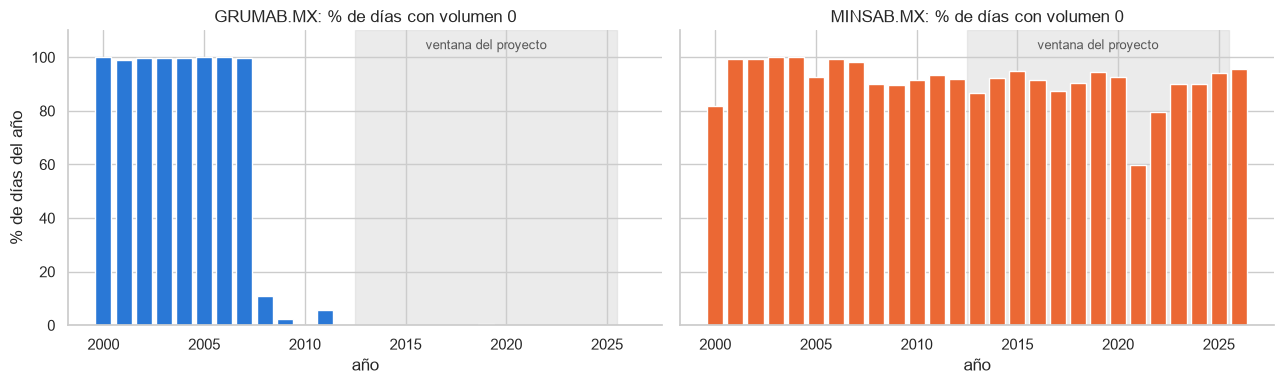

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for eje, (ticker, datos) in zip(ejes, diario.items()):
    tabla = resumen_operacion(datos)
    eje.bar(tabla.index, tabla["pct_volumen_cero"], color=COLORES[ticker], width=0.8)
    eje.axvspan(2012.5, 2025.5, color="0.85", alpha=0.5, zorder=0)
    eje.text(2019, 103, "ventana del proyecto", ha="center", fontsize=9, color="0.35")
    eje.set_title(f"{ticker}: % de días con volumen 0")
    eje.set_ylim(0, 110)
    eje.set_xlabel("año")
ejes[0].set_ylabel("% de días del año")
fig.tight_layout()
fig.savefig(ruta_figuras / "bursatil_dias_sin_operacion.png", dpi=150)
plt.show()

Gruma no tiene operación real del 2000 al 2007: casi el 100 % de los días tiene volumen 0 y la mayoría repite el cierre del día anterior. A partir del 2008 casi todos los días tienen operación, y del 2013 al 2025 prácticamente todos.

MINSAB no nos servirá para el análisis que queremos hacer, tendremos que trabajar con solo GRUMAB. La parte buena de esto es que es la empresa principal con la que queríamos realizar el análisis.

## Anomalías (*outliers*)

Buscamos días con movimientos fuera de lo normal en Gruma a partir de 2008.

### Coherencia de precios OHLC

Son los cuatro precios que normalmente se ven en la bolsa de valores:
- O: Open, precio con el que abrió.
- H: High, precio más alto que estuvo en el día.
- L: Low, precio más bajo que estuvo en el día.
- C: Close, precio con el que cerro en el día.

Usaremos tres técnicas para detectar outliers, dos sencillas y una un poco mas compleja:
- IQR
- Z-Score
- Isolation Forest.

Primero comprobemos que no haya incoherencias.

In [13]:
def incoherencias(datos):
    return pd.Series({
        "High < Low": (datos["High"] < datos["Low"]).sum(),
        "Close fuera de [Low, High]": (
            (datos["Close"] > datos["High"] * 1.0001) | (datos["Close"] < datos["Low"] * 0.9999)
        ).sum(),
        "Open fuera de [Low, High]": (
            (datos["Open"] > datos["High"] * 1.0001) | (datos["Open"] < datos["Low"] * 0.9999)
        ).sum(),
        "precio <= 0": (datos[["Open", "High", "Low", "Close"]] <= 0).any(axis=1).sum(),
    })


pd.DataFrame({t: incoherencias(d) for t, d in diario.items()})

,GRUMAB.MX,MINSAB.MX
High < Low,0,0
"Close fuera de [Low, High]",2,31
"Open fuera de [Low, High]",0,0
precio <= 0,0,0


Solo hay unos pocos días con el cierre fuera del rango Low–High: 2 en Gruma y 31 en Minsa. No hay precios en 0 ni días con High menor que Low. Son pocos casos, así que no los corregimos.

### Variables para la detección

Los precios de Gruma tienen una tendencia de largo plazo: pasaron de unos 35 MXN en
2013 a más de 350 MXN en 2025. Si usáramos los precios directamente, los métodos
marcarían como atípicos los días más baratos o más caros del periodo, no los días
con un comportamiento inusual. Por eso convertimos los precios en medidas relativas,
que se pueden comparar en cualquier año.

Usaremos estas variables:
- rendimiento: Close / Close del día anterior − 1 | Cuánto subió o bajó la acción
- rango: High - Low, que tanto se movio el precio dentro del mismo dia
- log_volumen:  cuantas acciones se negociaron en el dia. Se usa el logaritmo para estandarizar.


In [14]:
g = gruma.loc["2008":].copy()
g["log_ret"] = np.log(g["Close"]).diff()
g["rango_intradia"] = (g["High"] - g["Low"]) / g["Close"]
g["log_volumen"] = np.log1p(g["Volume"])
g = g.dropna(subset=["log_ret"])
g[["log_ret", "rango_intradia", "log_volumen"]].describe().round(4)

,log_ret,rango_intradia,log_volumen
count,4706.0000,4706.0000,4706.0000
mean,0.0005,0.0286,13.1965
std,0.0241,0.0202,1.5710
min,-0.8938,0.0000,0.0000
25%,-0.0092,0.0175,12.8642
50%,0.0000,0.0243,13.3523
75%,0.0101,0.0340,13.8453
max,0.2578,0.6410,16.9486


### Rango intercuartílico

Marcamos como atípicos los rendimientos fuera de Q1 − 3·IQR y Q3 + 3·IQR.

In [15]:
q1, q3 = g["log_ret"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 3 * iqr, q3 + 3 * iqr
g["out_iqr"] = (g["log_ret"] < lim_inf) | (g["log_ret"] > lim_sup)
print(f"Límites: [{lim_inf:.4f}, {lim_sup:.4f}]  ->  {g['out_iqr'].sum()} días atípicos "
      f"({g['out_iqr'].mean():.1%})")

Límites: [-0.0670, 0.0679]  ->  50 días atípicos (1.1%)


### *z*-score robusto (MAD)

Es como el z-score, pero con la mediana y la desviación absoluta mediana (MAD), que no se ven afectadas por los valores extremos. Marcamos los días con |z| > 3.5.

In [16]:
mediana = g["log_ret"].median()
mad = (g["log_ret"] - mediana).abs().median()
g["z_robusto"] = 0.6745 * (g["log_ret"] - mediana) / mad
g["out_mad"] = g["z_robusto"].abs() > 3.5
print(f"MAD = {mad:.4f}  ->  {g['out_mad'].sum()} días atípicos ({g['out_mad'].mean():.1%})")

# Comparación con el z-score clásico, que se ve inflado por los propios extremos.
z_clasico = (g["log_ret"] - g["log_ret"].mean()) / g["log_ret"].std()
print(f"z-score clásico |z|>3.5 -> {(z_clasico.abs() > 3.5).sum()} días")

MAD = 0.0096  ->  119 días atípicos (2.5%)
z-score clásico |z|>3.5 -> 29 días


### Isolation Forest (multivariada)

Modelo que aísla las observaciones raras usando varias variables a la vez: rendimiento, rango del día y volumen. Le pedimos que marque el 1 % de los días.

In [17]:
variables_if = ["log_ret", "rango_intradia", "log_volumen"]
bosque = IsolationForest(contamination=0.01, random_state=42)
g["out_if"] = bosque.fit_predict(StandardScaler().fit_transform(g[variables_if])) == -1
print(f"Isolation Forest -> {g['out_if'].sum()} días atípicos")

Isolation Forest -> 27 días atípicos


### Comparación entre técnicas

Vemos cuántos días coinciden entre técnicas y en qué años aparecen.

In [18]:
tecnicas = ["out_iqr", "out_mad", "out_if"]
coincidencia = pd.DataFrame(
    [[(g[a] & g[b]).sum() for b in tecnicas] for a in tecnicas], index=tecnicas, columns=tecnicas
)
print("Días marcados en común (diagonal = total por técnica):")
print(coincidencia, "\n")

g["n_tecnicas"] = g[tecnicas].sum(axis=1)
print("Días marcados por las tres técnicas:", (g["n_tecnicas"] == 3).sum())

Días marcados en común (diagonal = total por técnica):
         out_iqr  out_mad  out_if
out_iqr       50       50      22
out_mad       50      119      25
out_if        22       25      27 

Días marcados por las tres técnicas: 22


El z-score robusto es el que más días marca y el Isolation Forest el que menos. Los 50 días del IQR también los marca el MAD, y 22 días los marcan las tres técnicas.

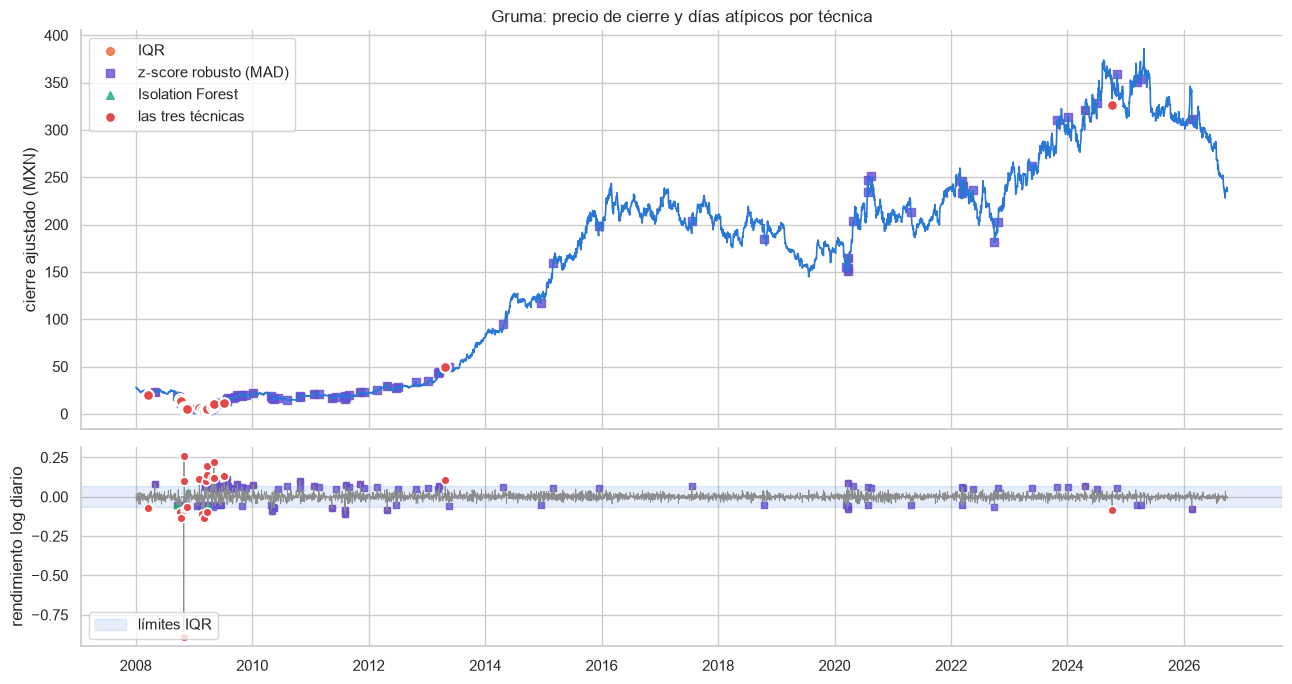

In [19]:
fig, ejes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, height_ratios=[2, 1])
consenso = g[g["n_tecnicas"] == 3]

# Un color y un marcador por técnica; en rojo los días que marcan las tres.
estilos = {
    "out_iqr": ("IQR", "#eb6834", "o"),
    "out_mad": ("z-score robusto (MAD)", "#6250d6", "s"),
    "out_if": ("Isolation Forest", "#1baf7a", "^"),
}

ejes[0].plot(g.index, g["Close"], color=COLORES["GRUMAB.MX"], lw=1.2)
ejes[1].plot(g.index, g["log_ret"], color="0.55", lw=0.6)
ejes[1].axhspan(lim_inf, lim_sup, color=COLORES["GRUMAB.MX"], alpha=0.12, label="límites IQR")

for columna, (nombre, color, marcador) in estilos.items():
    puntos = g[g[columna] & (g["n_tecnicas"] < 3)]
    ejes[0].scatter(puntos.index, puntos["Close"], s=30, color=color, marker=marcador,
                    alpha=0.8, label=nombre)
    ejes[1].scatter(puntos.index, puntos["log_ret"], s=20, color=color, marker=marcador,
                    alpha=0.8)

ejes[0].scatter(consenso.index, consenso["Close"], s=60, color=COLOR_ANOMALIA,
                edgecolor="white", lw=1.5, zorder=3, label="las tres técnicas")
ejes[1].scatter(consenso.index, consenso["log_ret"], s=40, color=COLOR_ANOMALIA,
                edgecolor="white", lw=1.2, zorder=3)

ejes[0].set_ylabel("cierre ajustado (MXN)")
ejes[0].set_title("Gruma: precio de cierre y días atípicos por técnica")
ejes[0].legend(loc="upper left")
ejes[1].set_ylabel("rendimiento log diario")
ejes[1].legend(loc="lower left")
fig.tight_layout()
fig.savefig(ruta_figuras / "bursatil_anomalias_gruma.png", dpi=150)
plt.show()

In [20]:
# Los 12 días más extremos con las técnicas que los marcan.
(g.loc[g["log_ret"].abs().nlargest(12).index,
       ["Close", "log_ret", "z_robusto", "Volume", "Dividends", "out_iqr", "out_mad", "out_if"]]
 .round(3))

,Close,log_ret,z_robusto,Volume,Dividends,out_iqr,out_mad,out_if
fecha,,,,,,,,
2008-10-29,4.759,-0.894,-62.532,0,0.0,True,True,True
2008-10-30,6.158,0.258,18.032,0,0.0,True,True,True
2009-05-06,10.071,0.220,15.357,10312000,0.0,True,True,True
2009-03-24,5.475,0.196,13.739,0,0.0,True,True,True
2009-03-23,4.498,0.139,9.759,353000,0.0,True,True,True
2008-10-10,11.632,-0.136,-9.501,161800,0.0,True,True,False
2008-10-09,13.324,-0.135,-9.454,0,0.0,True,True,True
2009-03-05,3.132,-0.134,-9.342,0,0.0,True,True,True
2009-07-09,11.836,0.133,9.294,1916800,0.0,True,True,True


In [21]:
# ¿En qué años se concentran los atípicos de consenso?
consenso.index.year.value_counts().sort_index().to_frame("dias_atipicos").T

fecha,2008,2009,2013,2024
dias_atipicos,9,11,1,1


Casi todos los atípicos están en 2008 y 2009, años de la crisis financiera. El más extremo es el 29 de octubre de 2008, con un rendimiento logarítmico de −0.89. Dentro de nuestra ventana (2013–2025) solo hay un día atípico en 2013 y uno en 2024.

### Anomalías en el rendimiento mensual

Aplicamos IQR y MAD al rendimiento mensual de 2013 a 2025, que es la granularidad que usaremos con los precios del maíz.

In [22]:
ventana = mensual.loc["2013":"2025"]
for ticker in ventana.columns:
    serie = ventana[ticker].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    mad = (serie - serie.median()).abs().median()
    out_iqr = (serie < q1 - 3 * iqr) | (serie > q3 + 3 * iqr)
    print(f"{ticker}: Q1={q1:.4f}, Q3={q3:.4f}, IQR={iqr:.4f}, MAD={mad:.4f}")
    if mad == 0 or iqr == 0:
        print("  IQR o MAD igual a 0: las reglas univariadas no son aplicables a esta serie.")
        print(f"  Meses con rendimiento distinto de 0: {(serie != 0).sum()} de {len(serie)}")
        continue
    out_mad = (0.6745 * (serie - serie.median()) / mad).abs() > 3.5
    print(f"  IQR: {out_iqr.sum()} meses | MAD: {out_mad.sum()} meses")
    for fecha, valor in serie[out_iqr | out_mad].items():
        print(f"  {fecha:%Y-%m}: {valor:+.3f}  (IQR={out_iqr[fecha]}, MAD={out_mad[fecha]})")

GRUMAB.MX: Q1=-0.0367, Q3=0.0585, IQR=0.0952, MAD=0.0476
  IQR: 0 meses | MAD: 1 meses
  2020-04: +0.267  (IQR=False, MAD=True)
MINSAB.MX: Q1=0.0000, Q3=0.0000, IQR=0.0000, MAD=0.0000
  IQR o MAD igual a 0: las reglas univariadas no son aplicables a esta serie.
  Meses con rendimiento distinto de 0: 70 de 156


En el rendimiento mensual de Gruma solo aparece un mes atípico, abril de 2020 (+26.7 %), y solo con MAD. En Minsa no se pueden aplicar estos métodos porque el IQR y la MAD valen 0: solo 70 de 156 meses tienen movimiento.

## Relaciones entre variables por visualización

Graficamos las variables para ver cómo se comportan y cómo se relacionan entre sí.

### Trayectoria de precios (base 100 en enero de 2013)

Ponemos ambas series en base 100 para compararlas en la misma escala.

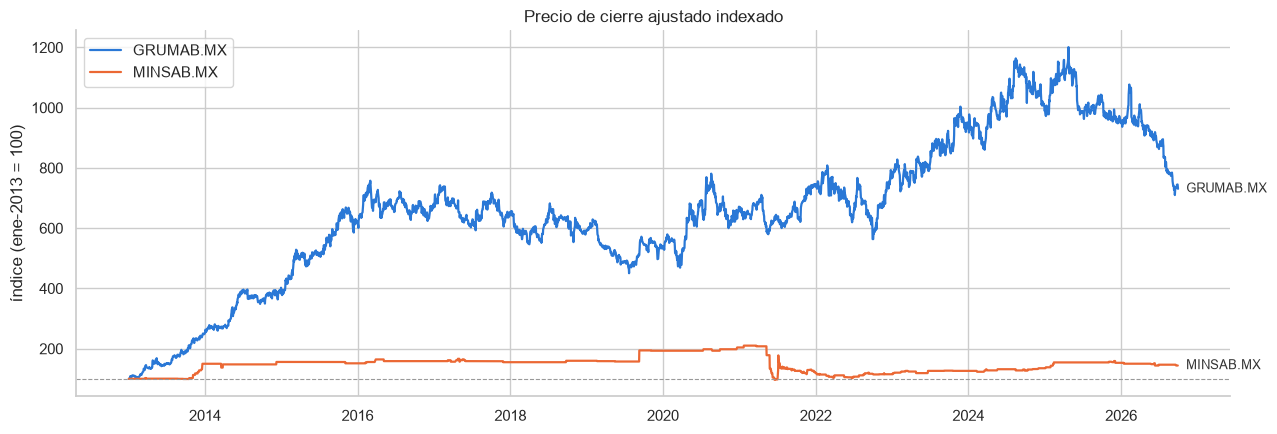

In [23]:
inicio = "2013-01-02"
fig, eje = plt.subplots(figsize=(13, 4.5))
for ticker, datos in diario.items():
    serie = datos.loc[inicio:, "Close"]
    indice = 100 * serie / serie.iloc[0]
    eje.plot(indice.index, indice, color=COLORES[ticker], lw=1.6, label=ticker)
    eje.annotate(ticker, (indice.index[-1], indice.iloc[-1]), xytext=(6, 0),
                 textcoords="offset points", va="center", color="0.2", fontsize=9)
eje.axhline(100, color="0.6", lw=0.8, ls="--")
eje.set_ylabel("índice (ene-2013 = 100)")
eje.set_title("Precio de cierre ajustado indexado")
eje.legend(loc="upper left")
fig.tight_layout()
fig.savefig(ruta_figuras / "bursatil_precios_indexados.png", dpi=150)
plt.show()

Desde 2013 Gruma multiplicó varias veces su precio, mientras que Minsa se mantuvo cerca de su nivel inicial.

### Distribución del rendimiento diario de Gruma frente a la normal

Comparamos el histograma con una distribución normal, con la gráfica Q-Q y con la prueba de Jarque-Bera.

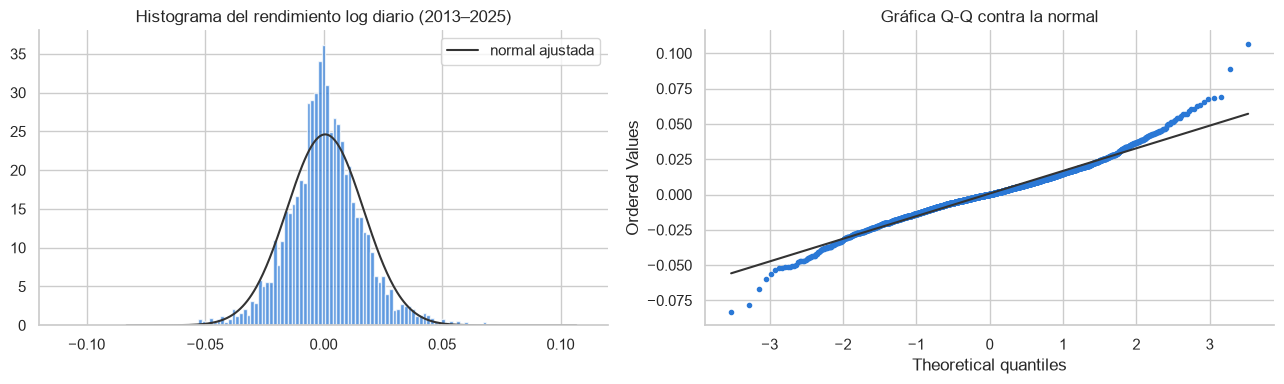

Asimetría: 0.25 | Curtosis en exceso: 2.36
Prueba de Jarque-Bera: SignificanceResult(statistic=np.float64(784.7055048947614), pvalue=np.float64(4.0120344411675326e-171))


In [24]:
r = g.loc["2013":"2025", "log_ret"]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
ejes[0].hist(r, bins=120, density=True, color=COLORES["GRUMAB.MX"], alpha=0.75)
x = np.linspace(r.min(), r.max(), 400)
ejes[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="0.2", lw=1.5, label="normal ajustada")
ejes[0].set_xlim(-0.12, 0.12)
ejes[0].set_title("Histograma del rendimiento log diario (2013–2025)")
ejes[0].legend()

stats.probplot(r, dist="norm", plot=ejes[1])
ejes[1].get_lines()[0].set(color=COLORES["GRUMAB.MX"], markersize=3)
ejes[1].get_lines()[1].set(color="0.2")
ejes[1].set_title("Gráfica Q-Q contra la normal")
fig.tight_layout()
plt.show()

print(f"Asimetría: {r.skew():.2f} | Curtosis en exceso: {r.kurt():.2f}")
print("Prueba de Jarque-Bera:", stats.jarque_bera(r))

Los rendimientos no siguen una distribución normal, tienen colas más pesadas: hay más días extremos de los que esperaríamos.

### Volatilidad y volumen

Vemos si los días con más movimiento tienen más volumen y cómo cambia la volatilidad en el tiempo.

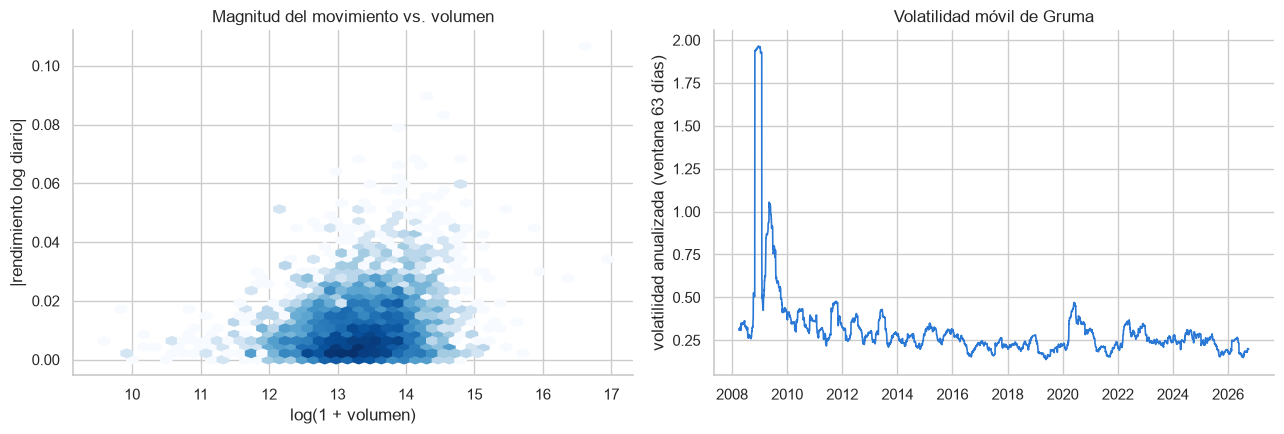

Spearman |r| vs volumen (2013-2025): 0.198


In [25]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
v = g.loc["2013":"2025"].query("Volume > 0")
ejes[0].hexbin(v["log_volumen"], v["log_ret"].abs(), gridsize=45, cmap="Blues", mincnt=1, bins="log")
ejes[0].set_xlabel("log(1 + volumen)")
ejes[0].set_ylabel("|rendimiento log diario|")
ejes[0].set_title("Magnitud del movimiento vs. volumen")

vol_movil = g["log_ret"].rolling(63).std() * np.sqrt(252)
ejes[1].plot(vol_movil.index, vol_movil, color=COLORES["GRUMAB.MX"], lw=1.2)
ejes[1].set_ylabel("volatilidad anualizada (ventana 63 días)")
ejes[1].set_title("Volatilidad móvil de Gruma")
fig.tight_layout()
plt.show()
print("Spearman |r| vs volumen (2013-2025):",
      round(stats.spearmanr(v["log_volumen"], v["log_ret"].abs()).statistic, 3))

Los días con más volumen tienden a moverse más, pero la relación es débil. La volatilidad se disparó en 2008 y tuvo otro pico en 2020.

### Estacionalidad del rendimiento mensual

Revisamos si el rendimiento cambia según el mes del año, con la prueba de Kruskal-Wallis.

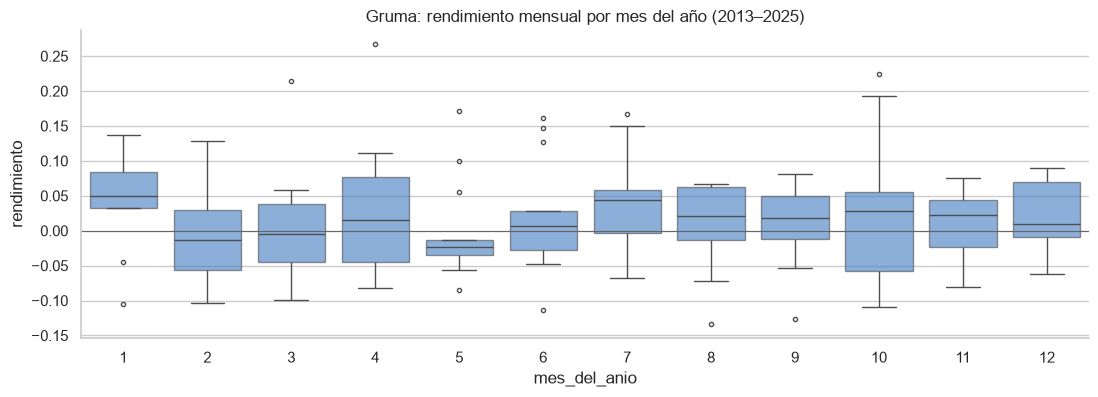

Kruskal-Wallis: KruskalResult(statistic=np.float64(9.435909998869306), pvalue=np.float64(0.5817229081709128))


In [26]:
estacional = ventana["GRUMAB.MX"].to_frame("rendimiento")
estacional["mes_del_anio"] = estacional.index.month
fig, eje = plt.subplots(figsize=(13, 4))
sns.boxplot(estacional, x="mes_del_anio", y="rendimiento", color=COLORES["GRUMAB.MX"], fliersize=3,
            boxprops={"alpha": 0.6}, ax=eje)
eje.axhline(0, color="0.4", lw=0.8)
eje.set_title("Gruma: rendimiento mensual por mes del año (2013–2025)")
plt.show()

# Kruskal-Wallis: ¿difiere la mediana entre meses?
grupos = [grupo["rendimiento"].values for _, grupo in estacional.groupby("mes_del_anio")]
print("Kruskal-Wallis:", stats.kruskal(*grupos))

No se ve un mes del año en el que a Gruma le vaya mejor o peor.

### Gruma vs. Minsa (rendimiento mensual)

Comparamos los rendimientos mensuales de ambas empresas.

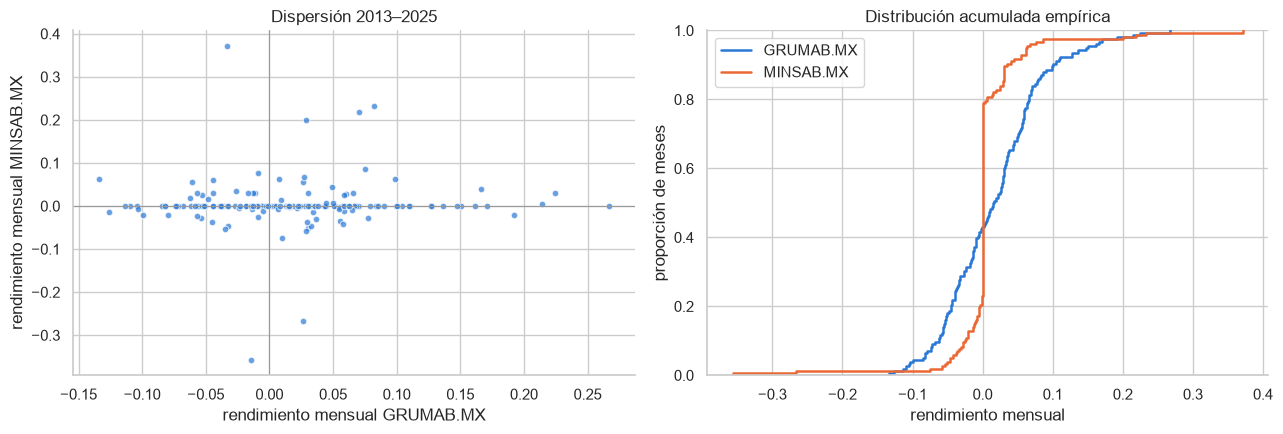

In [27]:
pares = ventana.dropna()
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].scatter(pares["GRUMAB.MX"], pares["MINSAB.MX"], s=22, color=COLORES["GRUMAB.MX"],
                alpha=0.7, edgecolor="white", lw=0.8)
ejes[0].axhline(0, color="0.6", lw=0.8)
ejes[0].axvline(0, color="0.6", lw=0.8)
ejes[0].set_xlabel("rendimiento mensual GRUMAB.MX")
ejes[0].set_ylabel("rendimiento mensual MINSAB.MX")
ejes[0].set_title("Dispersión 2013–2025")

for ticker in pares.columns:
    sns.ecdfplot(pares[ticker], ax=ejes[1], color=COLORES[ticker], label=ticker, lw=1.8)
ejes[1].set_xlabel("rendimiento mensual")
ejes[1].set_ylabel("proporción de meses")
ejes[1].set_title("Distribución acumulada empírica")
ejes[1].legend()
fig.tight_layout()
plt.show()

No hay relación entre los rendimientos de ambas empresas. Los puntos sobre la línea del 0 son los meses en los que Minsa no se movió.

## Correlación entre variables

Medimos qué tan relacionadas están las variables mensuales de ambas empresas de 2013 a 2025.

### Variables mensuales

Resumimos los datos diarios por mes: rendimiento, volatilidad, rango del día, volumen, días sin cambio y si hubo dividendo.

In [28]:
def variables_mensuales(datos):
    d = datos.copy()
    d["log_ret"] = np.log(d["Close"]).diff()
    d["rango"] = (d["High"] - d["Low"]) / d["Close"]
    d["sin_cambio"] = d["Close"].diff() == 0
    m = d.resample("ME")
    return pd.DataFrame({
        "ret": m["Close"].last().pct_change(),
        "vol": m["log_ret"].std() * np.sqrt(m["log_ret"].count()),
        "rango": m["rango"].mean(),
        "log_volumen": np.log1p(m["Volume"].sum()),
        "pct_sin_cambio": m["sin_cambio"].mean(),
        "dividendo": (m["Dividends"].sum() > 0).astype(int),
    })


abrev = {"GRUMAB.MX": "gruma", "MINSAB.MX": "minsa"}
vars_mes = pd.concat(
    {abrev[t]: variables_mensuales(d) for t, d in diario.items()}, axis=1
).loc["2013":"2025"]
vars_mes.columns = [f"{a}_{b}" for a, b in vars_mes.columns]
vars_mes = vars_mes.dropna()
print(vars_mes.shape)
vars_mes.describe().T.round(3)

(156, 12)


,count,mean,std,min,25%,50%,75%,max
gruma_ret,156.0,0.017,0.071,-0.134,-0.037,0.015,0.058,0.267
gruma_vol,156.0,0.071,0.022,0.027,0.056,0.069,0.080,0.169
gruma_rango,156.0,0.026,0.006,0.016,0.022,0.025,0.030,0.058
gruma_log_volumen,156.0,16.564,0.398,15.826,16.249,16.614,16.802,17.824
gruma_pct_sin_cambio,156.0,0.003,0.013,0.000,0.000,0.000,0.000,0.091
gruma_dividendo,156.0,0.192,0.395,0.000,0.000,0.000,0.000,1.000
minsa_ret,156.0,0.005,0.060,-0.357,0.000,0.000,0.000,0.371
minsa_vol,156.0,0.022,0.052,0.000,0.000,0.000,0.030,0.463
minsa_rango,156.0,0.001,0.005,0.000,0.000,0.000,0.000,0.056
minsa_log_volumen,156.0,5.598,3.529,0.000,4.615,5.545,7.314,16.400


### Pearson vs. Spearman

Pearson mide relaciones lineales y es sensible a los extremos; Spearman usa rangos y es más robusta.

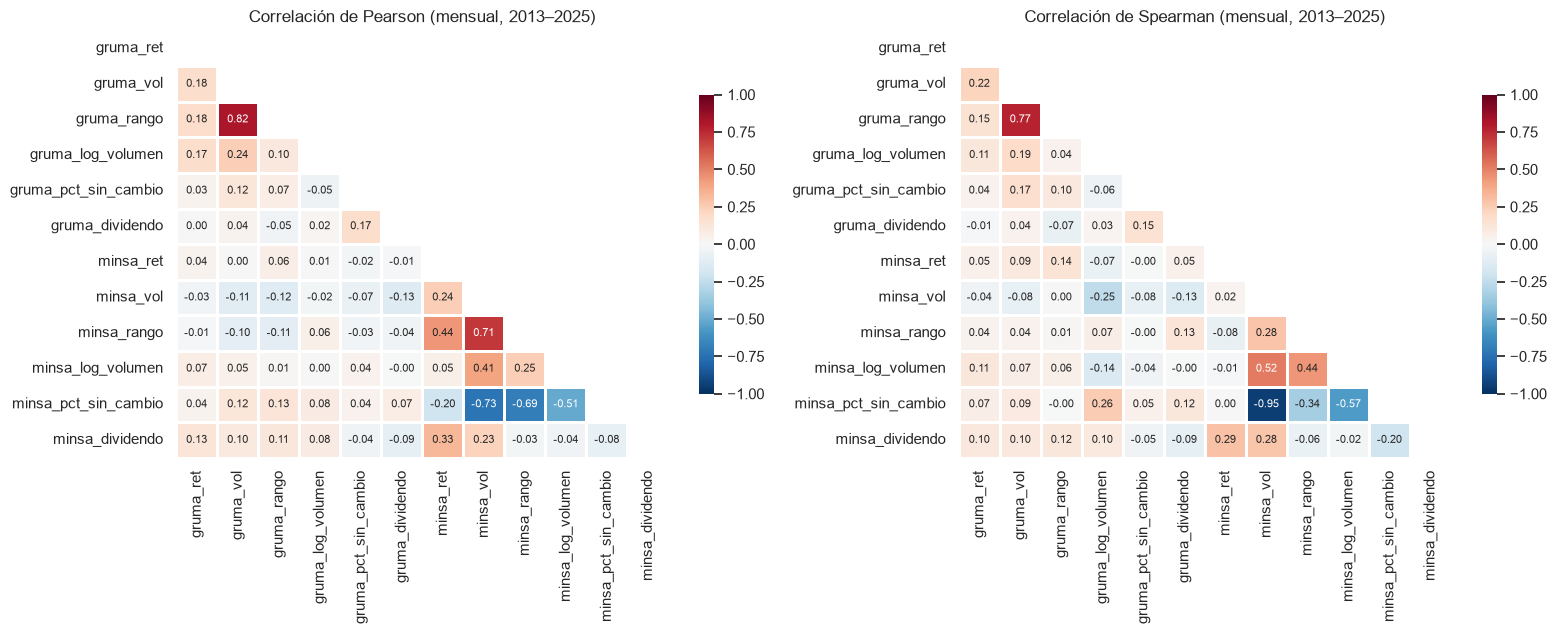

In [29]:
pearson = vars_mes.corr(method="pearson")
spearman = vars_mes.corr(method="spearman")
mascara = np.triu(np.ones_like(pearson, dtype=bool))

sns.set_style("white")
fig, ejes = plt.subplots(1, 2, figsize=(16, 6.5))
for eje, (nombre, matriz) in zip(ejes, [("Pearson", pearson), ("Spearman", spearman)]):
    sns.heatmap(matriz, mask=mascara, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True,
                fmt=".2f", annot_kws={"size": 8}, linewidths=1, linecolor="white",
                cbar_kws={"shrink": 0.7}, ax=eje)
    eje.set_title(f"Correlación de {nombre} (mensual, 2013–2025)")
fig.tight_layout()
fig.savefig(ruta_figuras / "bursatil_correlaciones.png", dpi=150)
plt.show()
sns.set_style("whitegrid")

In [30]:
# Pares con mayor diferencia entre Pearson y Spearman: señal de extremos o no linealidad.
diferencia = (pearson - spearman).where(~mascara).stack()
pd.DataFrame({
    "pearson": pearson.where(~mascara).stack(),
    "spearman": spearman.where(~mascara).stack(),
    "diferencia": diferencia,
}).reindex(diferencia.abs().sort_values(ascending=False).index).head(8).round(3)

pearson  spearman  diferencia
minsa_rango          minsa_ret            0.444    -0.076       0.520
                     minsa_vol            0.706     0.284       0.421
minsa_pct_sin_cambio minsa_rango         -0.690    -0.341      -0.349
minsa_vol            gruma_log_volumen   -0.024    -0.251       0.227
minsa_pct_sin_cambio minsa_vol           -0.729    -0.952       0.223
minsa_vol            minsa_ret            0.243     0.024       0.219
minsa_pct_sin_cambio minsa_ret           -0.196     0.002      -0.197
minsa_log_volumen    minsa_rango          0.245     0.442      -0.196

La volatilidad y el rango del día de Gruma prácticamente miden lo mismo. El rendimiento de Gruma casi no se relaciona con las demás variables. Las diferencias grandes entre Pearson y Spearman son todas de Minsa, por los pocos meses en que tuvo operación.

### Correlación Gruma–Minsa con significancia

Calculamos la correlación con su p-valor y una correlación móvil a 36 meses.

In [31]:
pares = mensual.loc["2013":"2025"].dropna()
pares_activos = pares[pares["MINSAB.MX"] != 0]
filas = []
for etiqueta, datos in [("todos los meses", pares), ("solo meses con movimiento en Minsa", pares_activos)]:
    p = stats.pearsonr(datos["GRUMAB.MX"], datos["MINSAB.MX"])
    s = stats.spearmanr(datos["GRUMAB.MX"], datos["MINSAB.MX"])
    filas.append({"muestra": etiqueta, "n": len(datos), "pearson": p.statistic, "p_pearson": p.pvalue,
                  "spearman": s.statistic, "p_spearman": s.pvalue})
pd.DataFrame(filas).round(3)

,muestra,n,pearson,p_pearson,spearman,p_spearman
0,todos los meses,156,0.036,0.652,0.054,0.504
1,solo meses con movimiento en Minsa,70,0.061,0.615,0.081,0.503


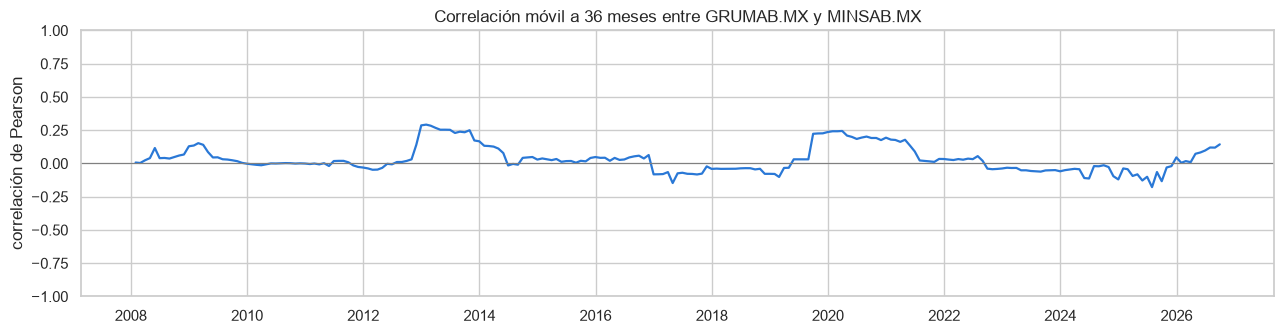

In [32]:
corr_movil = mensual["GRUMAB.MX"].rolling(36).corr(mensual["MINSAB.MX"]).loc["2008":]
fig, eje = plt.subplots(figsize=(13, 3.5))
eje.plot(corr_movil.index, corr_movil, color=COLORES["GRUMAB.MX"], lw=1.6)
eje.axhline(0, color="0.5", lw=0.8)
eje.set_ylim(-1, 1)
eje.set_ylabel("correlación de Pearson")
eje.set_title("Correlación móvil a 36 meses entre GRUMAB.MX y MINSAB.MX")
fig.tight_layout()
plt.show()

La correlación entre Gruma y Minsa es prácticamente 0 y no es significativa. A lo largo del tiempo sube y baja sin una dirección clara.

### Autocorrelación: ¿los rendimientos tienen memoria?

Revisamos si el rendimiento de un día se relaciona con el de días anteriores, tanto el rendimiento como su valor absoluto.

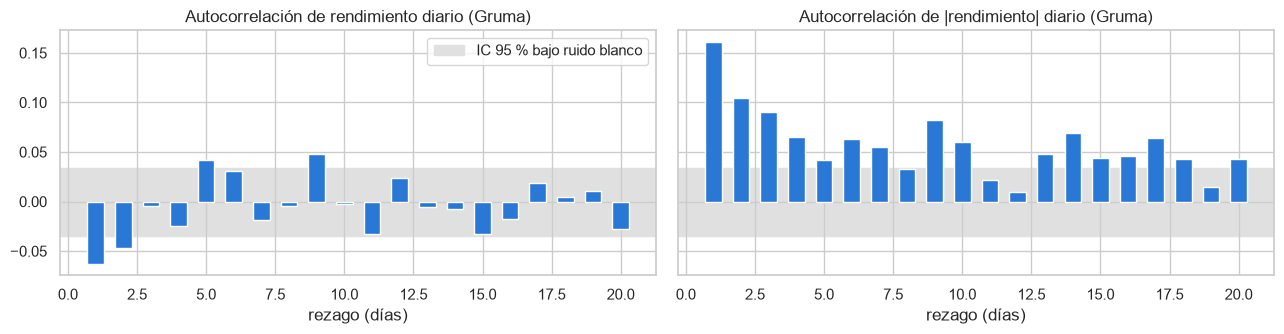

In [33]:
rezagos = range(1, 21)
r = g.loc["2013":"2025", "log_ret"]
acf = pd.DataFrame({
    "rendimiento": [r.autocorr(k) for k in rezagos],
    "|rendimiento|": [r.abs().autocorr(k) for k in rezagos],
}, index=rezagos)
banda = 1.96 / np.sqrt(len(r))

fig, ejes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for eje, columna in zip(ejes, acf.columns):
    eje.bar(acf.index, acf[columna], color=COLORES["GRUMAB.MX"], width=0.6)
    eje.axhspan(-banda, banda, color="0.88", zorder=0, label="IC 95 % bajo ruido blanco")
    eje.set_title(f"Autocorrelación de {columna} diario (Gruma)")
    eje.set_xlabel("rezago (días)")
ejes[0].legend()
fig.tight_layout()
plt.show()

El rendimiento de un día casi no dice nada del siguiente, pero el tamaño del movimiento sí: después de días con mucho movimiento suelen venir otros días con mucho movimiento.

## Reducción de dimensionalidad para visualización

Proyectamos las variables mensuales en dos dimensiones para ver si los meses forman grupos.

### PCA

Usamos las variables continuas de Gruma y el rendimiento de Minsa, estandarizadas.

In [34]:
columnas_pca = ["gruma_ret", "gruma_vol", "gruma_rango", "gruma_log_volumen", "minsa_ret"]
X = StandardScaler().fit_transform(vars_mes[columnas_pca])

pca = PCA().fit(X)
varianza = pd.DataFrame({
    "varianza_explicada": pca.explained_variance_ratio_,
    "acumulada": pca.explained_variance_ratio_.cumsum(),
}, index=[f"PC{i + 1}" for i in range(len(columnas_pca))]).round(3)
varianza

,varianza_explicada,acumulada
PC1,0.396,0.396
PC2,0.204,0.600
PC3,0.200,0.801
PC4,0.166,0.967
PC5,0.033,1.000


In [35]:
cargas = pd.DataFrame(pca.components_[:3].T, index=columnas_pca, columns=["PC1", "PC2", "PC3"])
cargas.round(3)

,PC1,PC2,PC3
gruma_ret,0.290,0.618,-0.009
gruma_vol,0.655,-0.242,-0.045
gruma_rango,0.635,-0.336,0.063
gruma_log_volumen,0.282,0.647,-0.224
minsa_ret,0.057,0.166,0.971


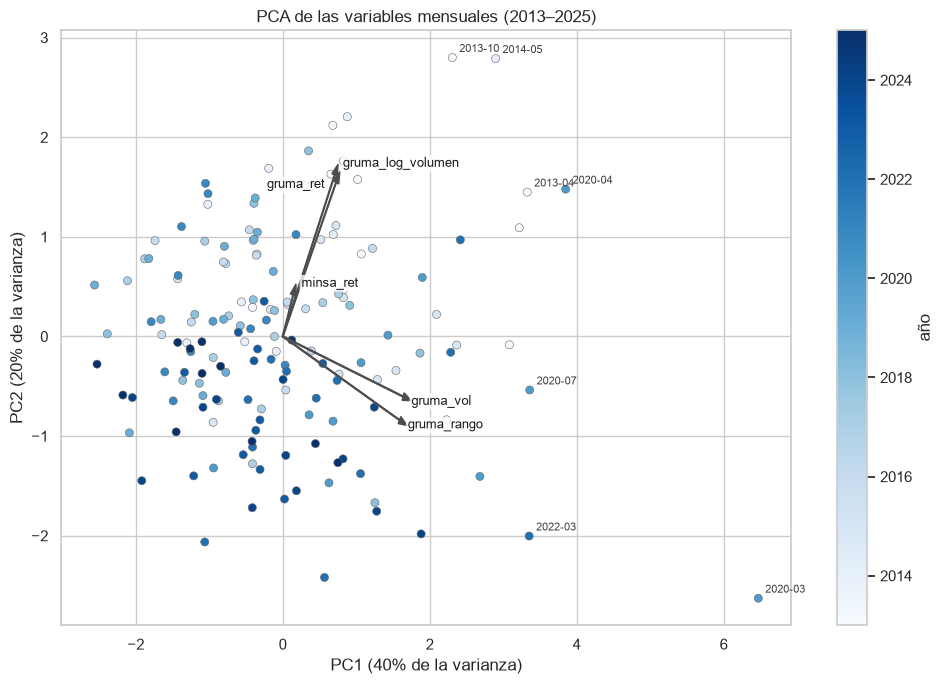

In [36]:
componentes = pca.transform(X)
proyeccion = pd.DataFrame(componentes[:, :2], columns=["PC1", "PC2"], index=vars_mes.index)
proyeccion["anio"] = proyeccion.index.year

fig, eje = plt.subplots(figsize=(10, 7))
puntos = eje.scatter(proyeccion["PC1"], proyeccion["PC2"], c=proyeccion["anio"], cmap="Blues",
                     s=34, edgecolor="0.4", lw=0.4)
fig.colorbar(puntos, ax=eje, label="año")

# Etiquetamos solo los meses más alejados del centro.
lejanos = (proyeccion[["PC1", "PC2"]] ** 2).sum(axis=1).nlargest(7).index
for fecha in lejanos:
    eje.annotate(fecha.strftime("%Y-%m"), proyeccion.loc[fecha, ["PC1", "PC2"]],
                 xytext=(5, 4), textcoords="offset points", fontsize=8, color="0.25")

# Flechas con la dirección de cada variable original.
escala = 2.5
for variable, (c1, c2) in cargas[["PC1", "PC2"]].iterrows():
    eje.arrow(0, 0, c1 * escala, c2 * escala, color="0.3", width=0.01, head_width=0.08, zorder=4)
    # Separamos las etiquetas de gruma_ret y gruma_log_volumen.
    desplazamiento = (-8, -4) if variable == "gruma_ret" else (6, 6 * np.sign(c2))
    eje.annotate(variable, (c1 * escala, c2 * escala), xytext=desplazamiento,
                 textcoords="offset points", ha="right" if variable == "gruma_ret" else "left",
                 fontsize=9,
                 color="0.1", zorder=5,
                 bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.8})

eje.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
eje.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)")
eje.set_title("PCA de las variables mensuales (2013–2025)")
fig.tight_layout()
fig.savefig(ruta_figuras / "bursatil_pca.png", dpi=150)
plt.show()

Con dos componentes se explica el 60 % de la varianza. El PC1 está relacionado con la volatilidad y el rango del día, y el PC2 con el rendimiento y el volumen. El rendimiento de Minsa queda casi solo en el PC3. El mes más alejado es marzo de 2020.

### t-SNE

t-SNE acomoda cerca los meses que se parecen. Coloreamos por nivel de volatilidad y por signo del rendimiento.

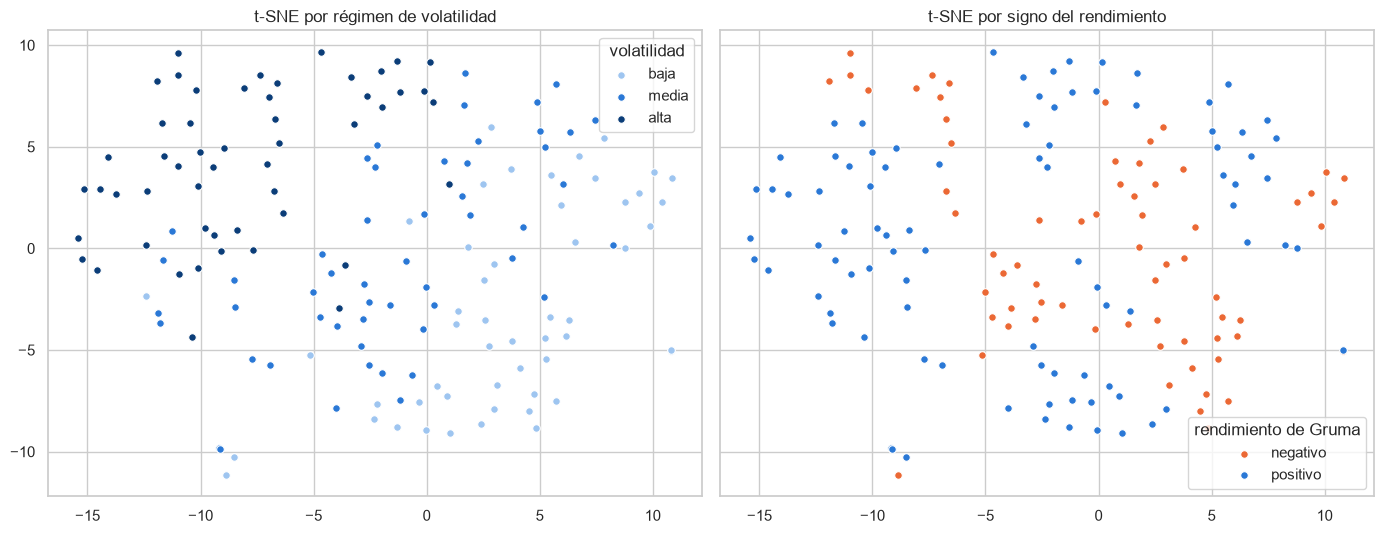

In [37]:
tsne = TSNE(n_components=2, perplexity=25, random_state=42, init="pca")
incrustado = pd.DataFrame(tsne.fit_transform(X), columns=["tsne_1", "tsne_2"], index=vars_mes.index)
incrustado["regimen_volatilidad"] = pd.qcut(vars_mes["gruma_vol"], 3, labels=["baja", "media", "alta"])
incrustado["signo_ret"] = np.where(vars_mes["gruma_ret"] >= 0, "positivo", "negativo")

colores_regimen = {"baja": "#9ec5f0", "media": "#2a78d6", "alta": "#0b3d78"}
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for regimen, grupo in incrustado.groupby("regimen_volatilidad", observed=True):
    ejes[0].scatter(grupo["tsne_1"], grupo["tsne_2"], s=30, color=colores_regimen[regimen],
                    edgecolor="white", lw=0.8, label=regimen)
ejes[0].legend(title="volatilidad")
ejes[0].set_title("t-SNE por régimen de volatilidad")

for (signo, grupo), color in zip(incrustado.groupby("signo_ret"), ["#eb6834", "#2a78d6"]):
    ejes[1].scatter(grupo["tsne_1"], grupo["tsne_2"], s=30, color=color, edgecolor="white",
                    lw=0.8, label=signo)
ejes[1].legend(title="rendimiento de Gruma")
ejes[1].set_title("t-SNE por signo del rendimiento")
fig.tight_layout()
fig.savefig(ruta_figuras / "bursatil_tsne.png", dpi=150)
plt.show()

Los meses se ordenan según la volatilidad, pero no se forman grupos separados.